# Implémentation d'Algorithmes d'Optimisation Différentiable

Gradient à pas fixe, pas optimal (Armijo), gradient conjugué (Fletcher-Reeves) et Quasi-Newton (BFGS), testés sur $f(x, y) = x^2 + 3y^2$. La documentation complète est dans le `README.md`.

## Outils symboliques et configuration initiale
Le gradient de la fonction test $f(x, y) = x^2 + 3y^2$ est calculé de manière exacte avec SymPy (pas de différences finies), puis converti en fonction NumPy via `lambdify`.

In [1]:
import numpy as np
import sympy as sp

# Définition symbolique pour calculer les gradients de manière exacte via Sympy
x_sym, y_sym = sp.symbols('x y')
# Fonction test : f(x, y) = x^2 + 3*y^2 (fonction convexe simple)
f_symbolique = x_sym**2 + 3 * y_sym**2

# Conversion en fonctions Python exploitables par Numpy
f_numerique = sp.lambdify((x_sym, y_sym), f_symbolique, 'numpy')
gradient_symbolique = [sp.diff(f_symbolique, x_sym), sp.diff(f_symbolique, y_sym)]
gradient_numerique = sp.lambdify((x_sym, y_sym), gradient_symbolique, 'numpy')


def evaluer_fonction(point_actuel):
    """Évalue la fonction objective f(x, y) pour un vecteur numpy donné."""
    return f_numerique(point_actuel[0], point_actuel[1])


def evaluer_gradient(point_actuel):
    """Calcule le gradient de la fonction f au point_actuel."""
    grad_x, grad_y = gradient_numerique(point_actuel[0], point_actuel[1])
    return np.array([grad_x, grad_y], dtype=float)


print("f(x, y) =", f_symbolique)
print("grad f  =", gradient_symbolique)

f(x, y) = x**2 + 3*y**2
grad f  = [2*x, 6*y]


### Descente de gradient à pas fixe
Mise à jour : $x_{k+1} = x_k - \alpha \nabla f(x_k)$, arrêt lorsque $\|\nabla f(x_k)\| < \varepsilon$.

In [2]:
def descente_gradient_pas_fixe(point_depart, pas_apprentissage, nombre_iterations_max, seuil_tolerance):
    """
    Optimisation par descente de gradient à pas fixe.

    Paramètres :
    - point_depart : vecteur numpy initial [x0, y0]
    - pas_apprentissage : taille du pas (constante)
    - nombre_iterations_max : plafond des boucles d'optimisation
    - seuil_tolerance : condition d'arrêt sur la norme du gradient
    """
    point_actuel = np.array(point_depart, dtype=float)
    historique_points = [point_actuel.copy()]

    for iteration in range(nombre_iterations_max):
        gradient_actuel = evaluer_gradient(point_actuel)

        # Condition d'arrêt si le gradient est proche de zéro (minimum atteint)
        norme_gradient = np.linalg.norm(gradient_actuel)
        if norme_gradient < seuil_tolerance:
            print(f"[Pas Fixe] Convergence atteinte à l'itération {iteration}.")
            break

        # Mise à jour du point : x_k+1 = x_k - alpha * grad_f(x_k)
        point_actuel = point_actuel - pas_apprentissage * gradient_actuel
        historique_points.append(point_actuel.copy())

    return point_actuel, historique_points

### Descente de gradient à pas optimal (Armijo)
Le pas $\alpha$ est réduit par rétrocession (facteur 0,5) à partir de $\alpha = 1$ jusqu'à satisfaire la condition d'Armijo :
$f(x_k + \alpha d_k) \le f(x_k) + c\,\alpha\,\nabla f(x_k)^T d_k$, avec $c = 10^{-4}$.

In [3]:
def recherche_pas_armijo(point_actuel, direction_descente, gradient_actuel):
    """
    Recherche linéaire de pas optimal via la condition d'Armijo.
    """
    produit_scalaire_direction = np.dot(gradient_actuel, direction_descente)
    pas_actuel = 1.0
    coefficient_diminution = 0.5
    constante_armijo = 1e-4
    nombre_essais_max = 50

    valeur_actuelle = evaluer_fonction(point_actuel)

    for essai in range(nombre_essais_max):
        point_teste = point_actuel + pas_actuel * direction_descente
        valeur_testee = evaluer_fonction(point_teste)

        # Condition d'Armijo (suffisante baisse)
        condition_suffisante = valeur_actuelle + constante_armijo * pas_actuel * produit_scalaire_direction
        if valeur_testee <= condition_suffisante:
            break

        pas_actuel = pas_actuel * coefficient_diminution

    return pas_actuel


def descente_gradient_pas_optimal(point_depart, nombre_iterations_max, seuil_tolerance):
    """
    Optimisation par descente de gradient avec pas optimal variable (Armijo).
    """
    point_actuel = np.array(point_depart, dtype=float)
    historique_points = [point_actuel.copy()]

    for iteration in range(nombre_iterations_max):
        gradient_actuel = evaluer_gradient(point_actuel)
        norme_gradient = np.linalg.norm(gradient_actuel)

        if norme_gradient < seuil_tolerance:
            print(f"[Pas Optimal] Convergence atteinte à l'itération {iteration}.")
            break

        direction_descente = -gradient_actuel
        pas_optimal = recherche_pas_armijo(point_actuel, direction_descente, gradient_actuel)

        point_actuel = point_actuel + pas_optimal * direction_descente
        historique_points.append(point_actuel.copy())

    return point_actuel, historique_points

### Gradient conjugué (Fletcher-Reeves)
Direction : $d_{k+1} = -\nabla f(x_{k+1}) + \beta_k d_k$ avec $\beta_k^{FR} = \dfrac{\|\nabla f(x_{k+1})\|^2}{\|\nabla f(x_k)\|^2}$.

In [4]:
def descente_gradient_conjugue(point_depart, nombre_iterations_max, seuil_tolerance):
    """
    Optimisation par gradient conjugué (méthode de Fletcher-Reeves).
    """
    point_actuel = np.array(point_depart, dtype=float)
    historique_points = [point_actuel.copy()]

    gradient_actuel = evaluer_gradient(point_actuel)
    direction_descente = -gradient_actuel

    for iteration in range(nombre_iterations_max):
        norme_gradient = np.linalg.norm(gradient_actuel)
        if norme_gradient < seuil_tolerance:
            print(f"[Gradient Conjugué] Convergence atteinte à l'itération {iteration}.")
            break

        # Recherche du pas optimal le long de la direction conjuguée
        pas_optimal = recherche_pas_armijo(point_actuel, direction_descente, gradient_actuel)

        nouveau_point = point_actuel + pas_optimal * direction_descente
        nouveau_gradient = evaluer_gradient(nouveau_point)

        # Calcul du coefficient beta de Fletcher-Reeves
        norme_carre_ancien = np.dot(gradient_actuel, gradient_actuel)
        norme_carre_nouveau = np.dot(nouveau_gradient, nouveau_gradient)

        if norme_carre_ancien == 0:
            beta_fletcher_reeves = 0.0
        else:
            beta_fletcher_reeves = norme_carre_nouveau / norme_carre_ancien

        # Mise à jour de la direction de descente conjuguée
        direction_descente = -nouveau_gradient + beta_fletcher_reeves * direction_descente

        point_actuel = nouveau_point
        gradient_actuel = nouveau_gradient
        historique_points.append(point_actuel.copy())

    return point_actuel, historique_points

### Quasi-Newton (BFGS)
Direction : $d_k = -H_k \nabla f(x_k)$. Mise à jour de l'approximation de la hessienne inverse, avec $s_k = x_{k+1}-x_k$, $y_k = \nabla f_{k+1}-\nabla f_k$ et $\rho_k = 1/(y_k^T s_k)$ :

$$H_{k+1} = (I - \rho_k s_k y_k^T)\,H_k\,(I - \rho_k y_k s_k^T) + \rho_k s_k s_k^T$$

In [5]:
def algorithme_quasi_newton_bfgs(point_depart, nombre_iterations_max, seuil_tolerance):
    """
    Optimisation par Quasi-Newton (Méthode BFGS) from scratch.
    Approximation de la matrice hessienne inverse de manière itérative.
    """
    point_actuel = np.array(point_depart, dtype=float)
    dimension_espace = len(point_actuel)

    # Initialisation de la matrice hessienne inverse estimée à la matrice identité
    matrice_hessienne_inverse = np.eye(dimension_espace)
    historique_points = [point_actuel.copy()]

    gradient_actuel = evaluer_gradient(point_actuel)

    for iteration in range(nombre_iterations_max):
        norme_gradient = np.linalg.norm(gradient_actuel)
        if norme_gradient < seuil_tolerance:
            print(f"[Quasi-Newton BFGS] Convergence atteinte à l'itération {iteration}.")
            break

        # Direction de recherche Quasi-Newton : d = - H * g
        direction_descente = -np.dot(matrice_hessienne_inverse, gradient_actuel)

        # Recherche du pas optimal
        pas_optimal = recherche_pas_armijo(point_actuel, direction_descente, gradient_actuel)

        nouveau_point = point_actuel + pas_optimal * direction_descente
        nouveau_gradient = evaluer_gradient(nouveau_point)

        # Variations (s = delta_x, y = delta_g)
        variation_position = nouveau_point - point_actuel
        variation_gradient = nouveau_gradient - gradient_actuel

        produit_scalaire_sy = np.dot(variation_position, variation_gradient)

        # Mise à jour BFGS de la hessienne inverse si le produit scalaire est valide
        if produit_scalaire_sy > 1e-10:
            identite_matrice = np.eye(dimension_espace)
            terme_s = variation_position.reshape(-1, 1)
            terme_y = variation_gradient.reshape(-1, 1)

            facteur_correction = 1.0 / produit_scalaire_sy
            partie_gauche = identite_matrice - facteur_correction * np.dot(terme_s, terme_y.T)
            partie_droite = identite_matrice - facteur_correction * np.dot(terme_y, terme_s.T)
            terme_central = facteur_correction * np.dot(terme_s, terme_s.T)

            matrice_hessienne_inverse = np.dot(partie_gauche, np.dot(matrice_hessienne_inverse, partie_droite)) + terme_central

        point_actuel = nouveau_point
        gradient_actuel = nouveau_gradient
        historique_points.append(point_actuel.copy())

    return point_actuel, historique_points

## Exécution et résultats

Tests comparatifs sur $f(x, y) = x^2 + 3y^2$ (minimum théorique en $[0, 0]$), depuis le point $[4, 5]$.

In [6]:
print("--- LANCEMENT DES TESTS D'OPTIMISATION ---")
point_initial = np.array([4.0, 5.0])
limite_iterations = 100
tolerance_arret = 1e-6

print(f"Point de départ : {point_initial}")
print(f"Fonction test : f(x, y) = x^2 + 3*y^2 (Minimum théorique en [0.0, 0.0])\n")

# Test 1 : Pas Fixe
resultat_fixe, hist_fixe = descente_gradient_pas_fixe(
    point_depart=point_initial,
    pas_apprentissage=0.1,
    nombre_iterations_max=limite_iterations,
    seuil_tolerance=tolerance_arret
)
print(f"Résultat Pas Fixe : {resultat_fixe} | Valeur f(x) = {evaluer_fonction(resultat_fixe)}\n")

# Test 2 : Pas Optimal
resultat_optimal, hist_optimal = descente_gradient_pas_optimal(
    point_depart=point_initial,
    nombre_iterations_max=limite_iterations,
    seuil_tolerance=tolerance_arret
)
print(f"Résultat Pas Optimal : {resultat_optimal} | Valeur f(x) = {evaluer_fonction(resultat_optimal)}\n")

# Test 3 : Gradient Conjugué
resultat_conjugue, hist_conjugue = descente_gradient_conjugue(
    point_depart=point_initial,
    nombre_iterations_max=limite_iterations,
    seuil_tolerance=tolerance_arret
)
print(f"Résultat Gradient Conjugué : {resultat_conjugue} | Valeur f(x) = {evaluer_fonction(resultat_conjugue)}\n")

# Test 4 : Quasi-Newton BFGS
resultat_bfgs, hist_bfgs = algorithme_quasi_newton_bfgs(
    point_depart=point_initial,
    nombre_iterations_max=limite_iterations,
    seuil_tolerance=tolerance_arret
)
print(f"Résultat Quasi-Newton (BFGS) : {resultat_bfgs} | Valeur f(x) = {evaluer_fonction(resultat_bfgs)}\n")

--- LANCEMENT DES TESTS D'OPTIMISATION ---
Point de départ : [4. 5.]
Fonction test : f(x, y) = x^2 + 3*y^2 (Minimum théorique en [0.0, 0.0])

[Pas Fixe] Convergence atteinte à l'itération 72.
Résultat Pas Fixe : [4.21249167e-07 1.11503726e-28] | Valeur f(x) = 1.7745086042373232e-13

[Pas Optimal] Convergence atteinte à l'itération 25.
Résultat Pas Optimal : [ 1.19209290e-07 -1.49011612e-07] | Valeur f(x) = 8.08242361927114e-14

[Gradient Conjugué] Convergence atteinte à l'itération 30.
Résultat Gradient Conjugué : [-2.72946101e-07  4.43206089e-08] | Valeur f(x) = 8.039252309054508e-14

[Quasi-Newton BFGS] Convergence atteinte à l'itération 8.
Résultat Quasi-Newton (BFGS) : [-5.97133529e-10  7.05228293e-09] | Valeur f(x) = 1.4956065189765223e-16



### Comparaison visuelle des méthodes

Méthode                    Itérations      f(x_final)
Pas fixe                           72       1.775e-13
Pas optimal (Armijo)               25       8.082e-14
Gradient conjugué (FR)             30       8.039e-14
Quasi-Newton (BFGS)                 8       1.496e-16


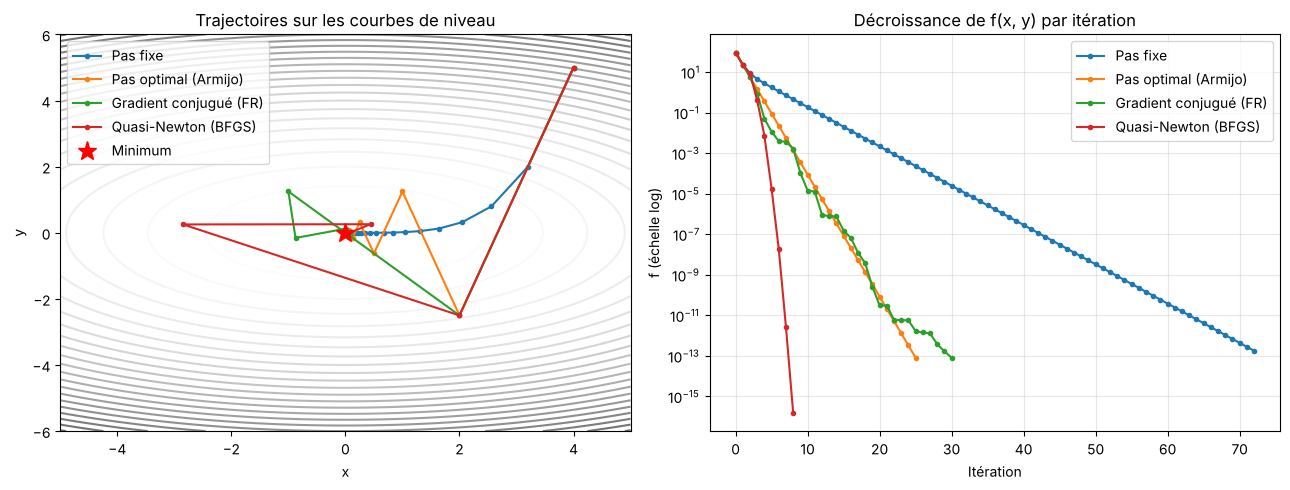

In [7]:
import matplotlib.pyplot as plt

historiques = {
    "Pas fixe": hist_fixe,
    "Pas optimal (Armijo)": hist_optimal,
    "Gradient conjugué (FR)": hist_conjugue,
    "Quasi-Newton (BFGS)": hist_bfgs,
}

print(f"{'Méthode':<26}{'Itérations':>11}{'f(x_final)':>16}")
for nom, h in historiques.items():
    print(f"{nom:<26}{len(h) - 1:>11}{evaluer_fonction(h[-1]):>16.3e}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Trajectoires sur les courbes de niveau
gx, gy = np.meshgrid(np.linspace(-5, 5, 200), np.linspace(-6, 6, 200))
axes[0].contour(gx, gy, f_numerique(gx, gy), levels=25, cmap="Greys", alpha=0.6)
for nom, h in historiques.items():
    h = np.array(h)
    axes[0].plot(h[:, 0], h[:, 1], marker="o", markersize=3, label=nom)
axes[0].plot(0, 0, "r*", markersize=14, label="Minimum")
axes[0].set_title("Trajectoires sur les courbes de niveau")
axes[0].set_xlabel("x"); axes[0].set_ylabel("y")
axes[0].legend()

# Décroissance de f
for nom, h in historiques.items():
    valeurs = [evaluer_fonction(p) for p in h]
    axes[1].semilogy(valeurs, marker="o", markersize=3, label=nom)
axes[1].set_title("Décroissance de f(x, y) par itération")
axes[1].set_xlabel("Itération"); axes[1].set_ylabel("f (échelle log)")
axes[1].grid(True, which="both", alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()